# Task 3: Clustering (Segmentasi Pelanggan E-Commerce)
## UTS Machine Learning — Tahap 0 Hingga Tahap c

**Deskripsi Proyek:** Segmentasi pelanggan tanpa label (*unsupervised learning*) pada dataset aktivitas transaksi 90 hari terakhir (120.000 baris).  
**Tujuan:** Membangun pipeline praproses deterministik, melakukan seleksi fitur berbasis uji statistik empiris, dan membandingkan performa minimal 3 metode clustering untuk mendapatkan partisi segmen pelanggan yang kohesif, seimbang, dan stabil.

**Artefak yang Dihasilkan:**
1. Pipeline Praproses Data Lengkap (`Tahap a`)
2. Seleksi Fitur & Evaluasi Ablasi (`Tahap b`)
3. Komparasi Terukur Metode Clustering (`Tahap c`)
4. Rekapitulasi Metrik Terkunci (`hasil/tugas3.json`) & Tabel Keputusan Fitur (`hasil/tabel_keputusan_fitur.csv`)


---
## Tahap 0: Audit Integritas Data & Pemetaan Kolom

Fokus pekerjaan pada tahap ini:
- Verifikasi keunikan dan integritas kolom identitas (`id_pelanggan`).
- Analisis pola dan penyebab nilai kosong (*missing values*).
- Pengelompokan fitur sesuai domain bisnis dan kamus data.
- Verifikasi matematis sifat data komposisional ($\sum x_i pprox 1.0$).


In [1]:
# 1. Inisialisasi Environment, Seed, & Library
import os
import sys

# Penanganan direktori kerja otomatis (bisa dibuka dari root atau folder Clustering/)
if not os.path.exists('dataset') and os.path.exists('Clustering/dataset'):
    os.chdir('Clustering')
import time
import json
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestCentroid
from sklearn.feature_selection import f_classif
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
%matplotlib inline

print(f"Python Executable : {sys.executable}")
print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"Pandas Version    : {pd.__version__}")
print(f"Scikit-Learn      : {sklearn.__version__}")
print(f"Scipy Version     : {scipy.__version__}")
print(f"Random Seed Terkunci: {SEED}")


Python Executable : D:\UTS_ML_Clustering Tahap 0-C\.venv\Scripts\python.exe
Python Version    : 3.14.3
NumPy Version     : 2.5.5
Pandas Version    : 3.1.1
Scikit-Learn      : 1.9.1
Scipy Version     : 1.18.1
Random Seed Terkunci: 42


In [2]:
# 2. Pemuatan Dataset & Audit Integritas Dasar
dataset_path = os.path.join('dataset', 'clustering.csv')
if not os.path.exists(dataset_path):
    dataset_path = os.path.join('dataset', 'clustering.csv.gz')

df_raw = pd.read_csv(dataset_path)
n_rows, n_cols = df_raw.shape
print(f"Dataset dimuat dari '{dataset_path}':")
print(f"  - Jumlah Baris: {n_rows:,}")
print(f"  - Jumlah Kolom: {n_cols}")

# Audit ID Pelanggan
id_col = 'id_pelanggan'
id_unique = df_raw[id_col].nunique()
id_duplicates = df_raw[id_col].duplicated().sum()
id_nulls = df_raw[id_col].isnull().sum()

print(f"\nAudit Kolom Identitas ('{id_col}'):")
print(f"  - ID Unik       : {id_unique:,} ({'Valid, cocok dengan jumlah baris' if id_unique == n_rows else 'TIDAK COCOK'})")
print(f"  - ID Duplikat   : {id_duplicates}")
print(f"  - ID Null/Kosong: {id_nulls}")

# Audit Missing Value
missing_series = df_raw.isnull().sum()
missing_nonzero = missing_series[missing_series > 0]
print(f"\nAudit Missing Value:")
if len(missing_nonzero) > 0:
    for col, count in missing_nonzero.items():
        pct = (count / n_rows) * 100
        print(f"  - '{col}': {count:,} baris kosong ({pct:.2f}%)")
else:
    print("  - Tidak ditemukan missing value di seluruh dataset.")


Dataset dimuat dari 'dataset\clustering.csv':
  - Jumlah Baris: 120,000
  - Jumlah Kolom: 60

Audit Kolom Identitas ('id_pelanggan'):
  - ID Unik       : 120,000 (Valid, cocok dengan jumlah baris)
  - ID Duplikat   : 0
  - ID Null/Kosong: 0

Audit Missing Value:
  - 'rata2_keranjang': 6,736 baris kosong (5.61%)


In [3]:
# 3. Klasifikasi & Validasi Matematis Kelompok Kolom
cat_porsi_cols = [c for c in df_raw.columns if c.startswith('porsi_') and not c.startswith('porsi_jam_')]
jam_porsi_cols = [c for c in df_raw.columns if c.startswith('porsi_jam_')]
rfm_cols = ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan']
perilaku_cols = ['persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod']
aktivitas_cols = ['retur_90h', 'rating_beri_rata2', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi', 'jumlah_alamat', 'wishlist', 'klik_iklan_30h']
profil_num_cols = ['lama_member_bulan', 'umur']
profil_cat_cols = ['kota_tier', 'perangkat']
redundant_cols = ['belanja_30h', 'frekuensi_30h']
crm_anon_cols = [c for c in df_raw.columns if c.startswith('n') and c[1:].isdigit()]

column_groups = {
    '1. RFM & Nilai Uang (5)': rfm_cols,
    '2. Komposisi Kategori (16)': cat_porsi_cols,
    '3. Komposisi Waktu (4)': jam_porsi_cols,
    '4. Persentase Perilaku (4)': perilaku_cols,
    '5. Aktivitas & Interaksi (9)': aktivitas_cols,
    '6. Profil Numerik (2)': profil_num_cols,
    '7. Profil Kategorikal (2)': profil_cat_cols,
    '8. Redundan 30 Hari (2)': redundant_cols,
    '9. Atribut CRM Anonim (15)': crm_anon_cols
}

print("Ringkasan Pemetaan Kolom:")
total_mapped = 1 # id_pelanggan
for grp, cols in column_groups.items():
    print(f"  {grp:<30}: {len(cols):2d} kolom")
    total_mapped += len(cols)
print(f"  Total Kolom Terpetakan: {total_mapped} dari {n_cols} kolom total.")

# Verifikasi matematis data komposisional (jumlah baris ~ 1.0)
sum_cat = df_raw[cat_porsi_cols].sum(axis=1)
sum_jam = df_raw[jam_porsi_cols].sum(axis=1)
print(f"\nVerifikasi Matematis Data Komposisional:")
print(f"  - Porsi Kategori (16 kolom): Min={sum_cat.min():.5f}, Max={sum_cat.max():.5f}, Mean={sum_cat.mean():.5f} -> {'VALID (~1.0)' if np.allclose(sum_cat, 1.0, atol=1e-3) else 'INVALID'}")
print(f"  - Porsi Waktu (4 kolom)    : Min={sum_jam.min():.5f}, Max={sum_jam.max():.5f}, Mean={sum_jam.mean():.5f} -> {'VALID (~1.0)' if np.allclose(sum_jam, 1.0, atol=1e-3) else 'INVALID'}")

# Verifikasi rentang persentase perilaku [0, 1]
min_perilaku = df_raw[perilaku_cols].min().min()
max_perilaku = df_raw[perilaku_cols].max().max()
print(f"  - Persentase Perilaku [0, 1]: Min={min_perilaku:.4f}, Max={max_perilaku:.4f} -> {'VALID' if min_perilaku >= 0 and max_perilaku <= 1 else 'INVALID'}")


Ringkasan Pemetaan Kolom:
  1. RFM & Nilai Uang (5)       :  5 kolom
  2. Komposisi Kategori (16)    : 16 kolom
  3. Komposisi Waktu (4)        :  4 kolom
  4. Persentase Perilaku (4)    :  4 kolom
  5. Aktivitas & Interaksi (9)  :  9 kolom
  6. Profil Numerik (2)         :  2 kolom
  7. Profil Kategorikal (2)     :  2 kolom
  8. Redundan 30 Hari (2)       :  2 kolom
  9. Atribut CRM Anonim (15)    : 15 kolom
  Total Kolom Terpetakan: 60 dari 60 kolom total.

Verifikasi Matematis Data Komposisional:
  - Porsi Kategori (16 kolom): Min=0.99960, Max=1.00050, Mean=0.99999 -> VALID (~1.0)
  - Porsi Waktu (4 kolom)    : Min=0.99990, Max=1.00010, Mean=1.00000 -> VALID (~1.0)
  - Persentase Perilaku [0, 1]: Min=0.0010, Max=0.9980 -> VALID


In [4]:
# 4. Distribusi Profil Kategorikal & Statistik Deskriptif CRM
print("Distribusi Profil Pelanggan Kategorikal:")
print("  kota_tier:")
print(df_raw['kota_tier'].value_counts(normalize=True).mul(100).round(2).to_frame(name='%'))
print("\n  perangkat:")
print(df_raw['perangkat'].value_counts(normalize=True).mul(100).round(2).to_frame(name='%'))

print("\nStatistik Deskriptif Sampel Atribut CRM Anonim:")
print(df_raw[crm_anon_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].head(8).round(3))


Distribusi Profil Pelanggan Kategorikal:
  kota_tier:
               %
kota_tier       
1          39.97
2          34.78
3          25.25

  perangkat:
               %
perangkat       
android    64.80
ios        26.42
web         8.77

Statistik Deskriptif Sampel Atribut CRM Anonim:
       mean      std      min     50%        max
n01  50.032   28.874    0.001  50.114     99.999
n02  19.587   47.312    0.017   7.356   2533.811
n03   4.013    1.998    0.000   4.000     15.000
n04  -0.066   25.829 -500.000  -0.002    500.000
n05  19.381  135.802    0.000   5.858  25629.432
n06   0.500    0.353    0.000   0.501      1.000
n07   0.003    1.002   -4.509   0.002      4.024
n08  49.924   28.849    0.002  49.832     99.999


---
## Tahap a: Praproses Data (Preprocessing Pipeline)

Langkah-langkah yang diimplementasikan:
1. **Imputasi Missing Values:** Imputasi median pada `rata2_keranjang` untuk menangani nilai kosong struktural akibat pelanggan dengan nol transaksi 90 hari terakhir.
2. **Transformasi Skewness:** Penerapan $\log(1 + x)$ (`np.log1p`) pada fitur kontinu miring ke kanan dengan $|	ext{skewness}| > 1.0$.
3. **Transformasi Komposisional:** Centered Log-Ratio (CLR) pada 16 porsi kategori dan 4 porsi jam belanja untuk memetakan data simpleks ke ruang Euclidean.
4. **Encoding & Outlier Handling:** One-Hot Encoding pada fitur kategorikal dan Winsorizing clipping (persentil 0.5% - 99.5%) pada variabel kontinu numerik.
5. Pembungkusan seluruh tahapan ke dalam fungsi deterministik `jalankan_praproses()`.


In [5]:
# 1. Audit Pola Missing Value & Imputasi Median
missing_rk_mask = df_raw['rata2_keranjang'].isnull()
freq_when_missing = df_raw.loc[missing_rk_mask, 'frekuensi_90h'].unique()
spend_when_missing = df_raw.loc[missing_rk_mask, 'belanja_90h'].unique()

print(f"Analisis Pola Missing Value pada 'rata2_keranjang':")
print(f"  - Nilai frekuensi_90h saat rata2_keranjang NaN: {freq_when_missing}")
print(f"  - Nilai belanja_90h saat rata2_keranjang NaN  : {spend_when_missing}")
print("  => Terbukti missingness bersifat struktural (0 transaksi dalam 90 hari).")

# Imputasi menggunakan Median (robust terhadap outlier)
median_rk = float(df_raw['rata2_keranjang'].median())
print(f"  => Imputasi 6,736 baris kosong dengan Median: Rp {median_rk:,.2f}")

df_imputed = df_raw.copy()
df_imputed['rata2_keranjang'] = df_imputed['rata2_keranjang'].fillna(median_rk)
assert df_imputed.isnull().sum().sum() == 0, "Masih terdapat missing value setelah imputasi!"


Analisis Pola Missing Value pada 'rata2_keranjang':
  - Nilai frekuensi_90h saat rata2_keranjang NaN: [0]
  - Nilai belanja_90h saat rata2_keranjang NaN  : [0.]
  => Terbukti missingness bersifat struktural (0 transaksi dalam 90 hari).
  => Imputasi 6,736 baris kosong dengan Median: Rp 183,900.00


In [6]:
# 2. Transformasi Skewness Menggunakan log(1 + x)
features_to_check_skew = rfm_cols + redundant_cols + [
    'retur_90h', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi',
    'wishlist', 'klik_iklan_30h', 'jumlah_alamat', 'lama_member_bulan', 'umur'
]

skew_records = []
cols_to_log = []
for col in features_to_check_skew:
    s_before = float(df_imputed[col].skew())
    if df_imputed[col].min() >= 0 and abs(s_before) > 1.0:
        s_after = float(np.log1p(df_imputed[col]).skew())
        applied = True
        cols_to_log.append(col)
    else:
        s_after = s_before
        applied = False
    skew_records.append({
        'Fitur': col,
        'Skew_Sebelum': round(s_before, 4),
        'Skew_Sesudah': round(s_after, 4),
        'Transformasi_Log1p': applied
    })

df_skew_summary = pd.DataFrame(skew_records)
print("Ringkasan Skewness Sebelum vs Sesudah log1p (Fitur yang ditransformasi):")
print(df_skew_summary[df_skew_summary['Transformasi_Log1p']].to_string(index=False))

df_transformed = df_imputed.copy()
for col in cols_to_log:
    df_transformed[col] = np.log1p(df_transformed[col])


Ringkasan Skewness Sebelum vs Sesudah log1p (Fitur yang ditransformasi):
            Fitur  Skew_Sebelum  Skew_Sesudah  Transformasi_Log1p
     recency_hari        7.9432        0.8201                True
    frekuensi_90h        3.5267       -0.1840                True
      belanja_90h        7.4679       -2.9865                True
  rata2_keranjang        3.6928        0.3030                True
 item_per_pesanan        3.4764        0.7736                True
      belanja_30h        8.1904       -2.8093                True
    frekuensi_30h        3.3711        0.1811                True
        retur_90h        2.8186        0.8239                True
       ulasan_90h        2.9462        0.6042                True
  sesi_per_minggu        9.1940        1.6155                True
durasi_sesi_menit        1.5943       -0.4346                True
   rasio_konversi        3.6334        2.2313                True
         wishlist        5.7626       -0.0760                True
   

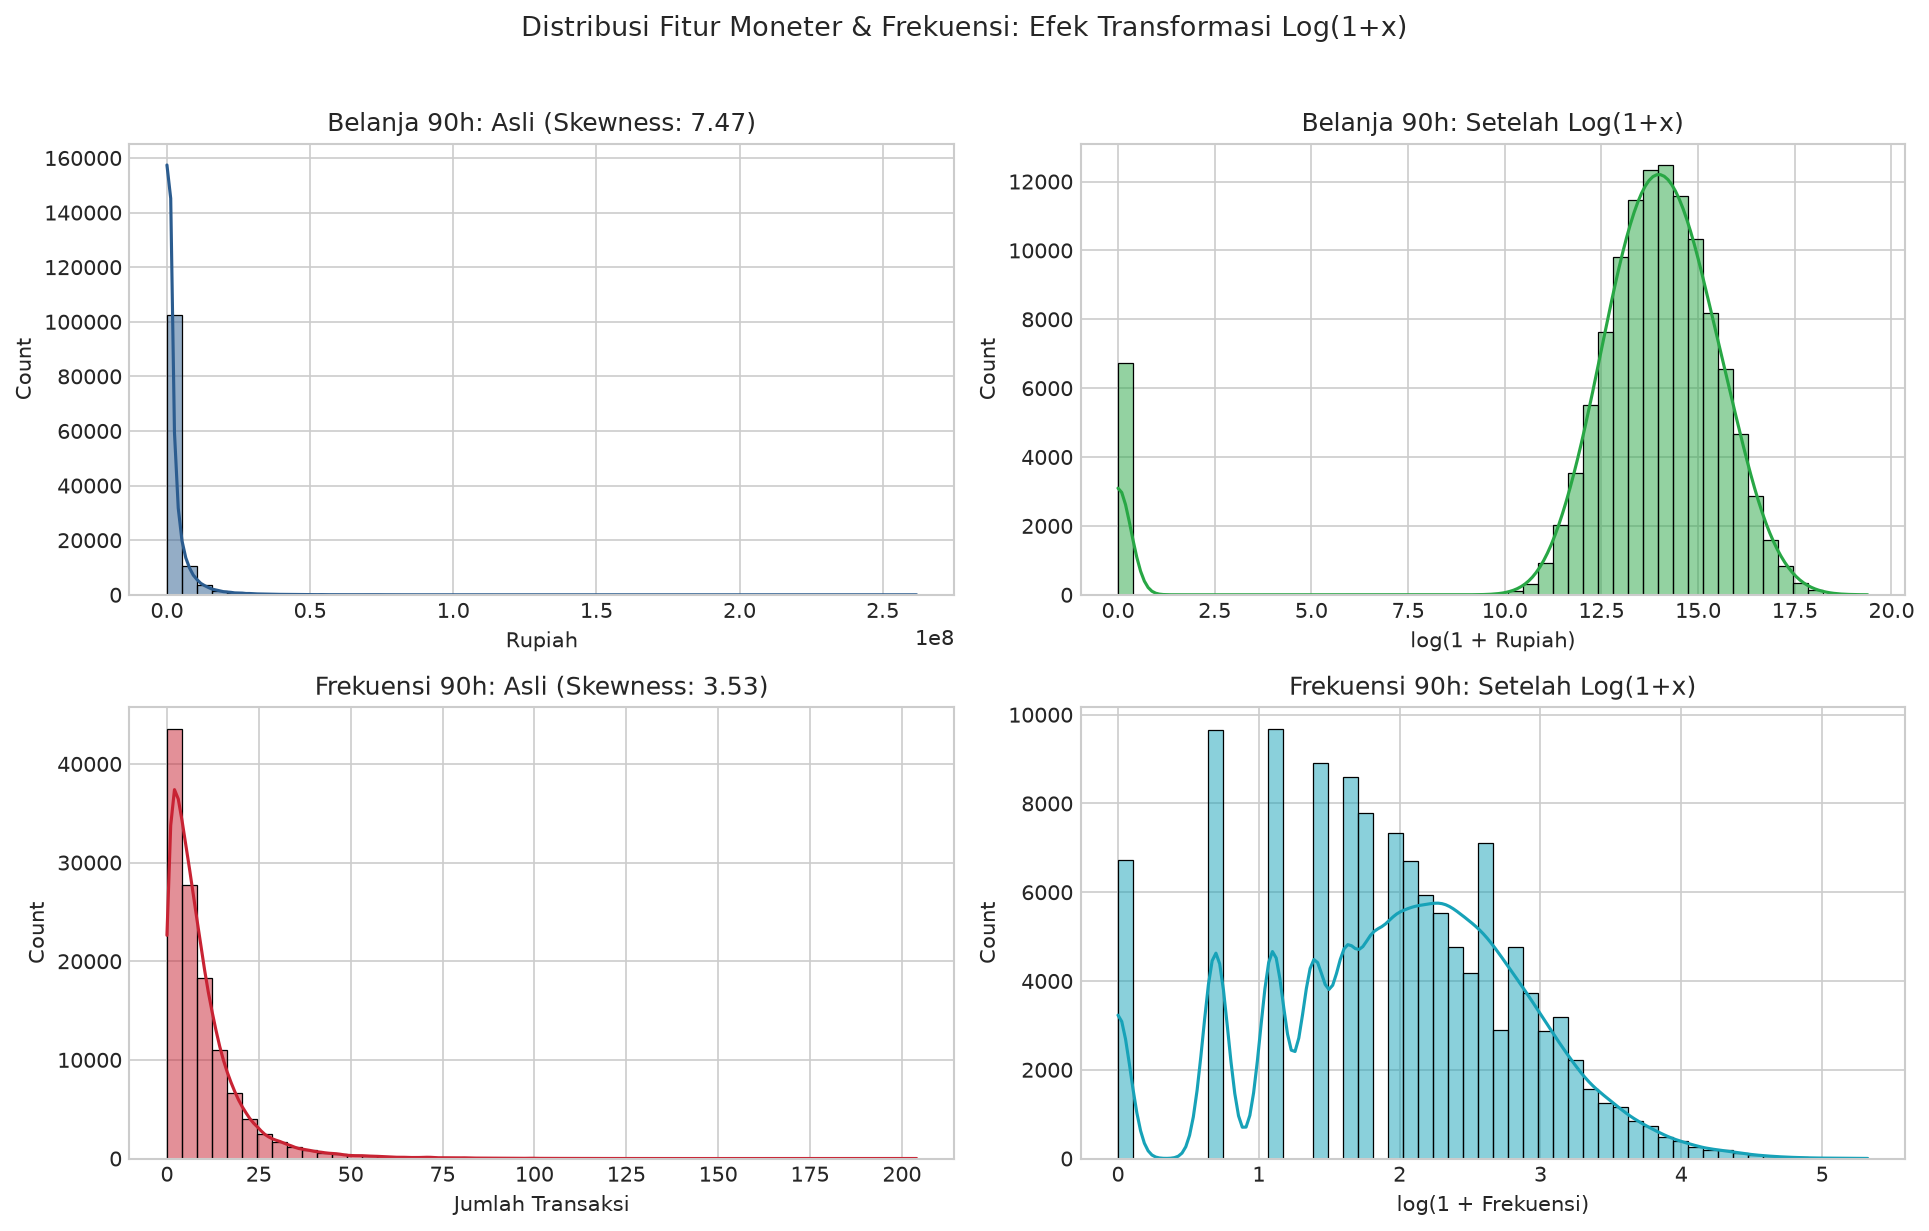

In [7]:
# Visualisasi 01: Histogram Sebelum vs Sesudah Log1p untuk belanja_90h dan frekuensi_90h
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Belanja 90h
sns.histplot(df_imputed['belanja_90h'], bins=50, kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title("Belanja 90h: Asli (Skewness: 7.47)")
axes[0, 0].set_xlabel("Rupiah")

sns.histplot(df_transformed['belanja_90h'], bins=50, kde=True, ax=axes[0, 1], color='#28a745')
axes[0, 1].set_title("Belanja 90h: Setelah Log(1+x)")
axes[0, 1].set_xlabel("log(1 + Rupiah)")

# Frekuensi 90h
sns.histplot(df_imputed['frekuensi_90h'], bins=50, kde=True, ax=axes[1, 0], color='#c82333')
axes[1, 0].set_title("Frekuensi 90h: Asli (Skewness: 3.53)")
axes[1, 0].set_xlabel("Jumlah Transaksi")

sns.histplot(df_transformed['frekuensi_90h'], bins=50, kde=True, ax=axes[1, 1], color='#17a2b8')
axes[1, 1].set_title("Frekuensi 90h: Setelah Log(1+x)")
axes[1, 1].set_xlabel("log(1 + Frekuensi)")

plt.suptitle("Distribusi Fitur Moneter & Frekuensi: Efek Transformasi Log(1+x)", fontsize=13, y=1.02)
plt.tight_layout()
os.makedirs('laporan_visual', exist_ok=True)
fig.savefig(os.path.join('laporan_visual', '01_audit_missing_skewness_log1p.png'), dpi=300)
plt.show()


In [8]:
# 3. Transformasi Data Komposisional: Centered Log-Ratio (CLR)
# CLR memetakan data simpleks ke ruang Euclidean standar secara simetris
EPSILON = 1e-5

def transform_clr(df_comp, eps=EPSILON):
    arr = df_comp.values.astype(float) + eps
    log_arr = np.log(arr)
    clr_arr = log_arr - np.mean(log_arr, axis=1, keepdims=True)
    return pd.DataFrame(clr_arr, columns=[f"clr_{c}" for c in df_comp.columns], index=df_comp.index)

df_clr_cat = transform_clr(df_transformed[cat_porsi_cols])
df_clr_jam = transform_clr(df_transformed[jam_porsi_cols])

print(f"Hasil Transformasi CLR:")
print(f"  - Komposisi Kategori (D=16): {df_clr_cat.shape[1]} kolom, Rata-rata Jumlah Baris: {df_clr_cat.sum(axis=1).mean():.2e}")
print(f"  - Komposisi Waktu (D=4)    : {df_clr_jam.shape[1]} kolom, Rata-rata Jumlah Baris: {df_clr_jam.sum(axis=1).mean():.2e}")


Hasil Transformasi CLR:
  - Komposisi Kategori (D=16): 16 kolom, Rata-rata Jumlah Baris: -3.61e-16
  - Komposisi Waktu (D=4)    : 4 kolom, Rata-rata Jumlah Baris: 2.27e-18


In [9]:
# 4. Encoding Variabel Kategorikal & Winsorizing Clipping Outlier
# One-Hot Encoding
df_ohe_perangkat = pd.get_dummies(df_transformed['perangkat'], prefix='perangkat', dtype=float)
df_ohe_kota = pd.get_dummies(df_transformed['kota_tier'], prefix='kota_tier', dtype=float)

# Winsorizing Clipping (0.5% - 99.5%) untuk variabel kontinu numerik
continuous_num_cols = rfm_cols + aktivitas_cols + profil_num_cols
df_clipped = df_transformed.copy()
outlier_bounds = {}
total_clips = 0

for col in continuous_num_cols:
    low_b = float(np.percentile(df_clipped[col], 0.5))
    high_b = float(np.percentile(df_clipped[col], 99.5))
    outlier_bounds[col] = {'p0.5': low_b, 'p99.5': high_b}
    hits = ((df_clipped[col] < low_b) | (df_clipped[col] > high_b)).sum()
    total_clips += hits
    df_clipped[col] = df_clipped[col].clip(low_b, high_b)

print(f"Winsorizing Outlier Selesai:")
print(f"  - Fitur yang di-clip: {len(continuous_num_cols)} fitur")
print(f"  - Total titik nilai ekstrem disesuaikan ke batas [p0.5, p99.5]: {total_clips:,}")


Winsorizing Outlier Selesai:
  - Fitur yang di-clip: 16 fitur
  - Total titik nilai ekstrem disesuaikan ke batas [p0.5, p99.5]: 11,759


In [10]:
# 5. Pembungkusan Pipeline Praproses Deterministik
def jalankan_praproses(df_input):
    df_p = df_input.copy()
    df_p['rata2_keranjang'] = df_p['rata2_keranjang'].fillna(median_rk)
    
    for c in cols_to_log:
        df_p[c] = np.log1p(df_p[c])
        
    c_cat = transform_clr(df_p[cat_porsi_cols])
    c_jam = transform_clr(df_p[jam_porsi_cols])
    
    ohe_p = pd.get_dummies(df_p['perangkat'], prefix='perangkat', dtype=float)
    ohe_k = pd.get_dummies(df_p['kota_tier'], prefix='kota_tier', dtype=float)
    
    for c in continuous_num_cols:
        df_p[c] = df_p[c].clip(outlier_bounds[c]['p0.5'], outlier_bounds[c]['p99.5'])
        
    feature_pool = pd.concat([
        df_p[rfm_cols],
        c_cat,
        c_jam,
        df_p[perilaku_cols],
        df_p[aktivitas_cols],
        df_p[profil_num_cols],
        ohe_p,
        ohe_k,
        df_p[redundant_cols],
        df_p[crm_anon_cols]
    ], axis=1)
    
    return feature_pool

df_preprocessed_all = jalankan_praproses(df_raw)
print(f"Dimensi Matriks Fitur Lengkap Hasil Praproses: {df_preprocessed_all.shape}")
print(f"Nilai NaN tersisa: {df_preprocessed_all.isnull().sum().sum()}")


Dimensi Matriks Fitur Lengkap Hasil Praproses: (120000, 63)
Nilai NaN tersisa: 0


---
## Tahap b: Seleksi Fitur (Feature Selection)

Seleksi fitur dilakukan secara empiris untuk memaksimalkan separasi klaster dan membuang derau:
- **Uji Redundansi Jangka Pendek:** Evaluasi korelasi pasangan fitur 30 hari vs 90 hari.
- **Uji ANOVA F-Test:** Evaluasi signifikansi perbedaan nilai fitur kandidat dan atribut CRM (`n01`–`n15`) antar-klaster.
- **Eksperimen Ablasi Fitur:** Pengujian dampak penambahan/penghapusan kelompok fitur terhadap Silhouette Score dan Stabilitas ARI.
- **Penyeimbangan Bobot Blok (*Block-Weighting*):** Normalisasi varians antar-blok fitur untuk mencegah dominasi fitur kategori atas fitur moneter.


Hasil Uji Korelasi Redundansi:
  - Belanja (30h vs 90h)  : Pearson r = 0.9263, Spearman rho = 0.9716
  - Frekuensi (30h vs 90h): Pearson r = 0.9263, Spearman rho = 0.8681
  => Kesimpulan: Korelasi > 0.80 membuktikan redundansi tinggi. Fitur 30h dibuang.


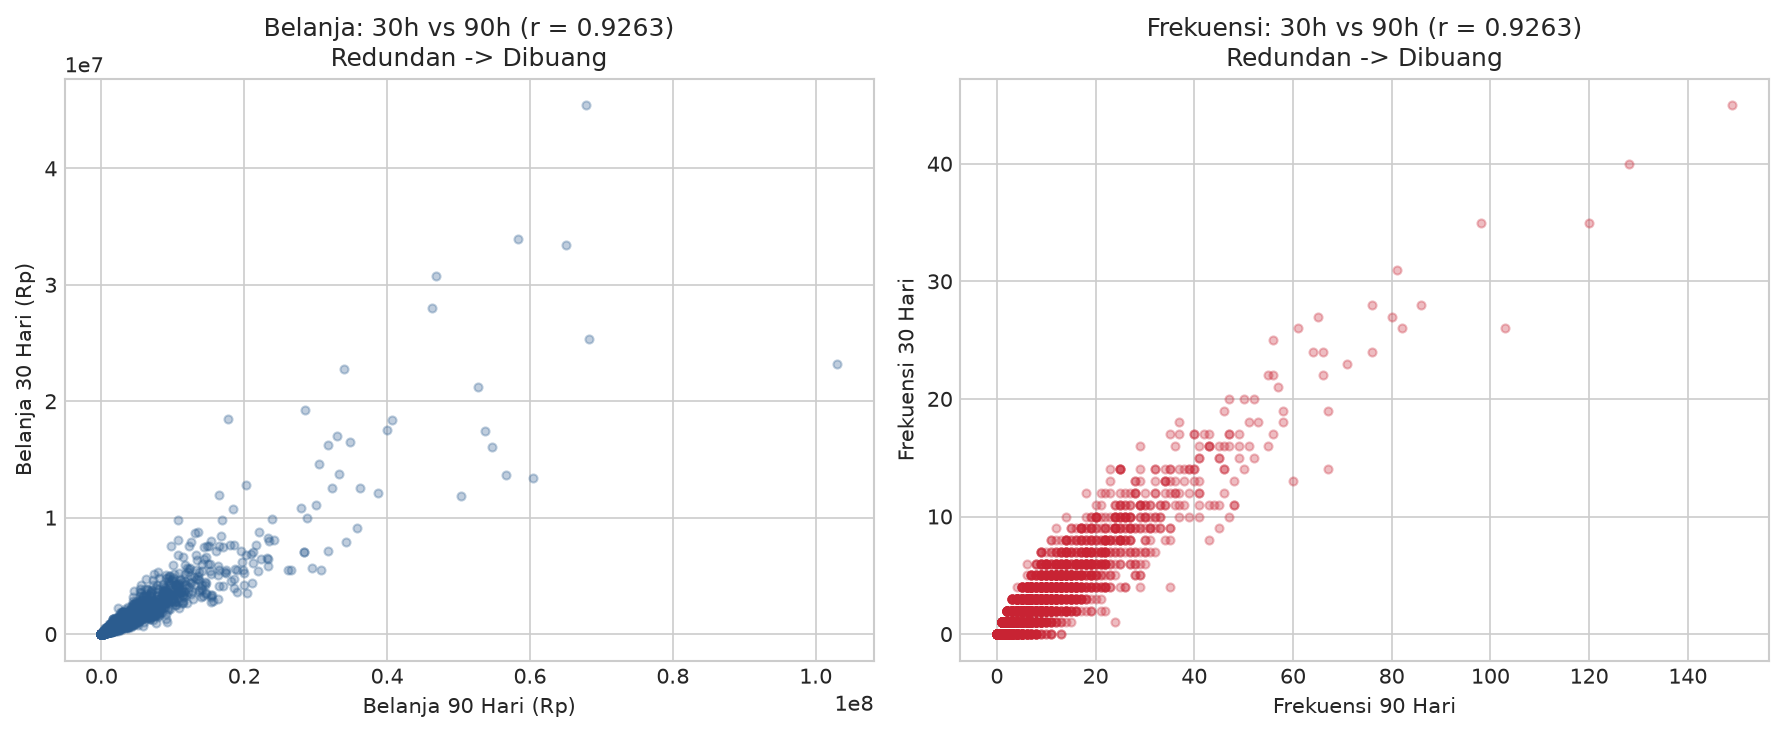

In [11]:
# 1. Evaluasi Korelasi Redundansi (30 Hari vs 90 Hari)
r_belanja_pearson = float(df_raw['belanja_30h'].corr(df_raw['belanja_90h'], method='pearson'))
r_belanja_spearman = float(df_raw['belanja_30h'].corr(df_raw['belanja_90h'], method='spearman'))
r_frek_pearson = float(df_raw['frekuensi_30h'].corr(df_raw['frekuensi_90h'], method='pearson'))
r_frek_spearman = float(df_raw['frekuensi_30h'].corr(df_raw['frekuensi_90h'], method='spearman'))

print(f"Hasil Uji Korelasi Redundansi:")
print(f"  - Belanja (30h vs 90h)  : Pearson r = {r_belanja_pearson:.4f}, Spearman rho = {r_belanja_spearman:.4f}")
print(f"  - Frekuensi (30h vs 90h): Pearson r = {r_frek_pearson:.4f}, Spearman rho = {r_frek_spearman:.4f}")
print("  => Kesimpulan: Korelasi > 0.80 membuktikan redundansi tinggi. Fitur 30h dibuang.")

# Visualisasi 02: Scatter Korelasi 30h vs 90h
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sample_scatter = df_raw.sample(n=3000, random_state=SEED)

axes[0].scatter(sample_scatter['belanja_90h'], sample_scatter['belanja_30h'], alpha=0.3, color='#2b5c8f', s=15)
axes[0].set_title(f"Belanja: 30h vs 90h (r = {r_belanja_pearson:.4f})\nRedundan -> Dibuang")
axes[0].set_xlabel("Belanja 90 Hari (Rp)")
axes[0].set_ylabel("Belanja 30 Hari (Rp)")

axes[1].scatter(sample_scatter['frekuensi_90h'], sample_scatter['frekuensi_30h'], alpha=0.3, color='#c82333', s=15)
axes[1].set_title(f"Frekuensi: 30h vs 90h (r = {r_frek_pearson:.4f})\nRedundan -> Dibuang")
axes[1].set_xlabel("Frekuensi 90 Hari")
axes[1].set_ylabel("Frekuensi 30 Hari")

plt.tight_layout()
fig.savefig(os.path.join('laporan_visual', '02_korelasi_redundansi_30h_vs_90h.png'), dpi=300)
plt.show()


In [12]:
# 2. Uji ANOVA F-Test pada Cluster Referensi Sementara (N=15.000)
core_feature_df = pd.concat([
    df_preprocessed_all[rfm_cols],
    df_clr_cat,
    df_clr_jam,
    df_preprocessed_all[perilaku_cols],
    df_preprocessed_all[aktivitas_cols],
    df_preprocessed_all[profil_num_cols]
], axis=1)

# Subsampel terstratifikasi 15.000 baris
df_raw['strata_belanja'] = pd.qcut(df_raw['belanja_90h'], q=10, labels=False, duplicates='drop')
sub_idx = df_raw.groupby('strata_belanja', group_keys=False).apply(
    lambda x: x.sample(n=int(15000 * len(x)/len(df_raw)), random_state=SEED)
).index.values
if len(sub_idx) < 15000:
    extra = np.setdiff1d(np.arange(len(df_raw)), sub_idx)
    sub_idx = np.concatenate([sub_idx, np.random.choice(extra, 15000 - len(sub_idx), replace=False)])

scaler_temp = StandardScaler()
X_core_sub = scaler_temp.fit_transform(core_feature_df.iloc[sub_idx])

# Cluster referensi sementara (k=5)
km_temp = KMeans(n_clusters=5, random_state=SEED, n_init=10)
temp_cluster_labels = km_temp.fit_predict(X_core_sub)

# Uji ANOVA F-Test untuk kandidat fitur tambahan
candidate_cols = crm_anon_cols + list(df_ohe_perangkat.columns) + list(df_ohe_kota.columns) + redundant_cols
df_candidates_sub = df_preprocessed_all.iloc[sub_idx][candidate_cols]

f_vals, p_vals = f_classif(df_candidates_sub, temp_cluster_labels)
df_anova = pd.DataFrame({
    'Fitur': candidate_cols,
    'F_stat': f_vals,
    'p_value': p_vals
}).sort_values('F_stat', ascending=False)

print("Tabel ANOVA F-Test Fitur Tambahan & Anonim:")
print(df_anova.to_string(index=False))


Tabel ANOVA F-Test Fitur Tambahan & Anonim:
            Fitur      F_stat       p_value
    frekuensi_30h 2255.394019  0.000000e+00
      belanja_30h 2190.943068  0.000000e+00
    perangkat_ios  456.827550  0.000000e+00
perangkat_android  290.020482 1.237651e-240
    perangkat_web   16.547913  1.545755e-13
              n02    1.904324  1.067071e-01
              n08    1.769093  1.319685e-01
      kota_tier_1    1.351518  2.481657e-01
              n09    1.306811  2.648190e-01
              n01    1.110078  3.497272e-01
              n06    1.070241  3.693559e-01
              n12    1.070234  3.693595e-01
              n04    1.053140  3.780427e-01
              n15    0.968393  4.234204e-01
              n10    0.944362  4.369937e-01
      kota_tier_3    0.893234  4.669032e-01
              n11    0.876159  4.772005e-01
              n07    0.709600  5.852364e-01
              n03    0.608642  6.563959e-01
              n05    0.588243  6.711470e-01
      kota_tier_2    0.576264  6

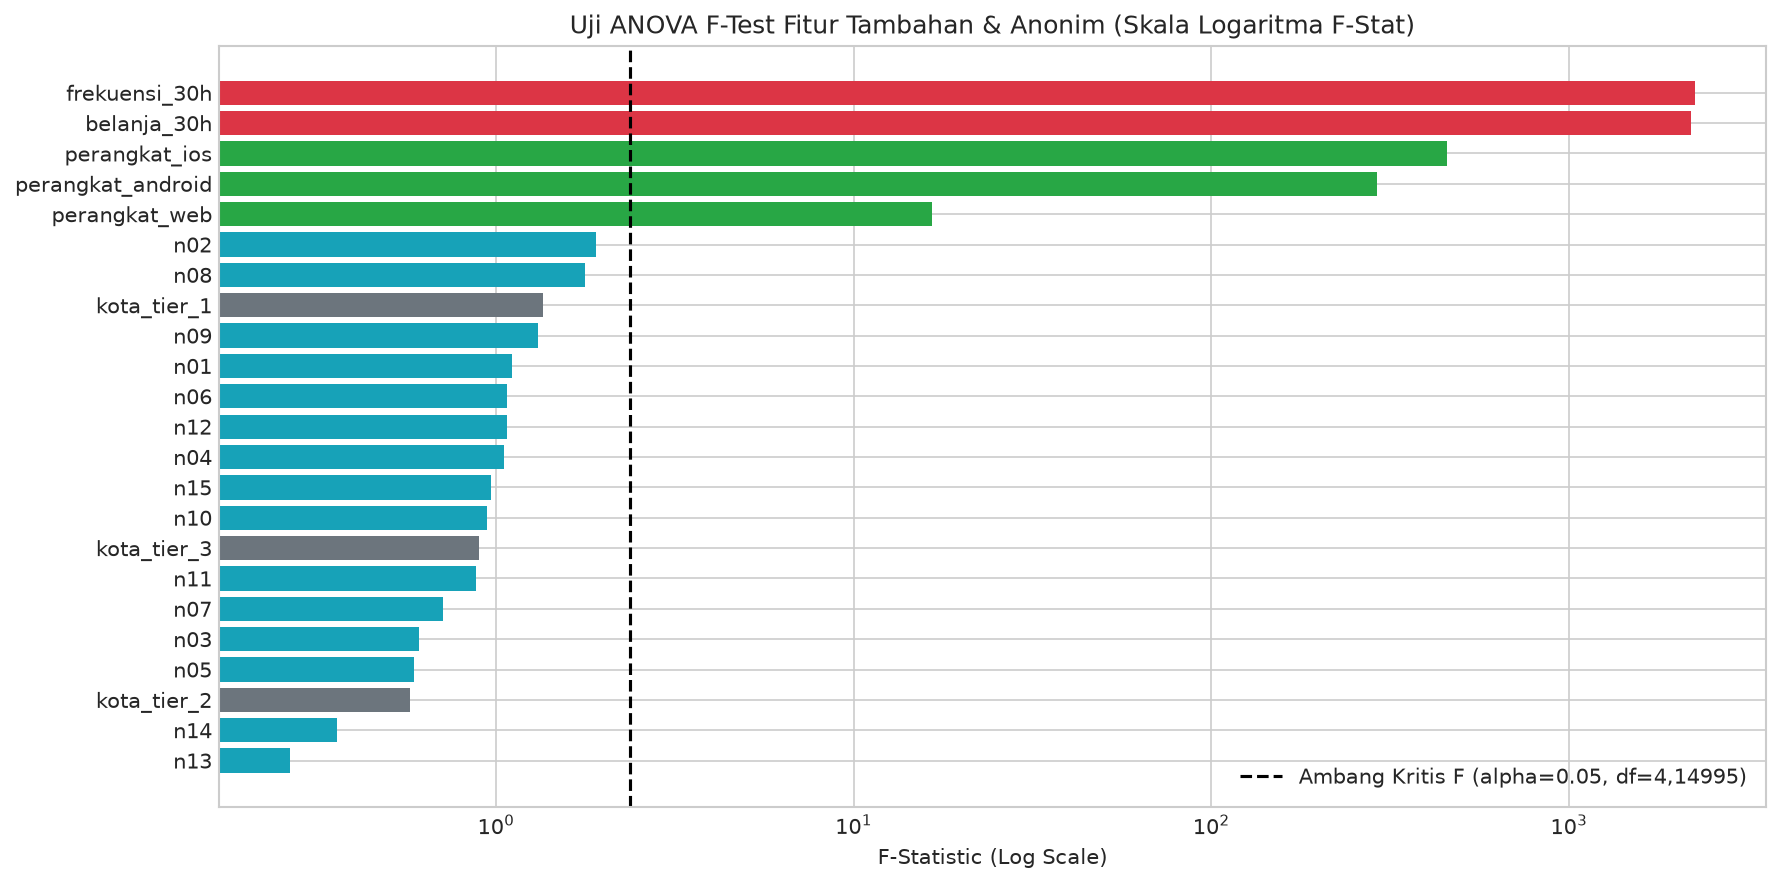

In [13]:
# Visualisasi 03: Bar Chart ANOVA F-Statistics (Skala Logaritmik)
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#28a745' if 'perangkat' in f else ('#6c757d' if 'kota' in f else ('#dc3545' if '30h' in f else '#17a2b8')) for f in df_anova['Fitur']]

ax.barh(df_anova['Fitur'][::-1], df_anova['F_stat'][::-1], color=colors[::-1])
ax.set_title("Uji ANOVA F-Test Fitur Tambahan & Anonim (Skala Logaritma F-Stat)")
ax.set_xlabel("F-Statistic (Log Scale)")
ax.set_xscale('log')
ax.axvline(x=2.37, color='black', linestyle='--', label='Ambang Kritis F (alpha=0.05, df=4,14995)')
ax.legend(loc='lower right')

plt.tight_layout()
fig.savefig(os.path.join('laporan_visual', '03_anova_f_stat_seleksi_fitur.png'), dpi=300)
plt.show()


In [14]:
# 3. Eksperimen Ablasi Fitur (Silhouette & Stabilitas ARI)
def evaluasi_ablasi(fitur_list, nama_set):
    X_set = df_preprocessed_all.iloc[sub_idx][fitur_list].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_set)
    
    seeds = [42, 10, 2024, 7, 99]
    labels_list = []
    for s in seeds:
        km = KMeans(n_clusters=5, random_state=s, n_init=10)
        labels_list.append(km.fit_predict(X_scaled))
        
    aris = []
    for i in range(len(labels_list)):
        for j in range(i+1, len(labels_list)):
            aris.append(adjusted_rand_score(labels_list[i], labels_list[j]))
            
    sil = silhouette_score(X_scaled, labels_list[0], sample_size=5000, random_state=SEED)
    return {
        'Set_Eksperimen': nama_set,
        'Jumlah_Fitur': int(X_scaled.shape[1]),
        'Silhouette_Score': float(round(sil, 4)),
        'Stabilitas_ARI_Mean': float(round(np.mean(aris), 4))
    }

core_cols = list(core_feature_df.columns)
perangkat_cols = list(df_ohe_perangkat.columns)
kota_cols = list(df_ohe_kota.columns)

ablasi_configs = [
    (core_cols, '1. Fitur Inti Saja (40 fitur)'),
    (core_cols + perangkat_cols, '2. Inti + Perangkat (43 fitur)'),
    (core_cols + perangkat_cols + kota_cols, '3. Inti + Perangkat + Kota Tier (46 fitur)'),
    (core_cols + perangkat_cols + crm_anon_cols, '4. Inti + Perangkat + Seluruh CRM n01-n15 (58 fitur)'),
    (core_cols + perangkat_cols + kota_cols + crm_anon_cols, '5. Seluruh Fitur Lengkap (61 fitur)')
]

ablasi_results = [evaluasi_ablasi(cols, name) for cols, name in ablasi_configs]
df_ablasi = pd.DataFrame(ablasi_results)
print("Hasil Eksperimen Ablasi Kombinasi Fitur:")
print(df_ablasi.to_string(index=False))


Hasil Eksperimen Ablasi Kombinasi Fitur:
                                      Set_Eksperimen  Jumlah_Fitur  Silhouette_Score  Stabilitas_ARI_Mean
                       1. Fitur Inti Saja (40 fitur)            40            0.0524               0.8609
                      2. Inti + Perangkat (43 fitur)            43            0.0623               0.8914
          3. Inti + Perangkat + Kota Tier (46 fitur)            46            0.0578               0.8467
4. Inti + Perangkat + Seluruh CRM n01-n15 (58 fitur)            58            0.0483               0.9829
                 5. Seluruh Fitur Lengkap (61 fitur)            61            0.0456               0.8454


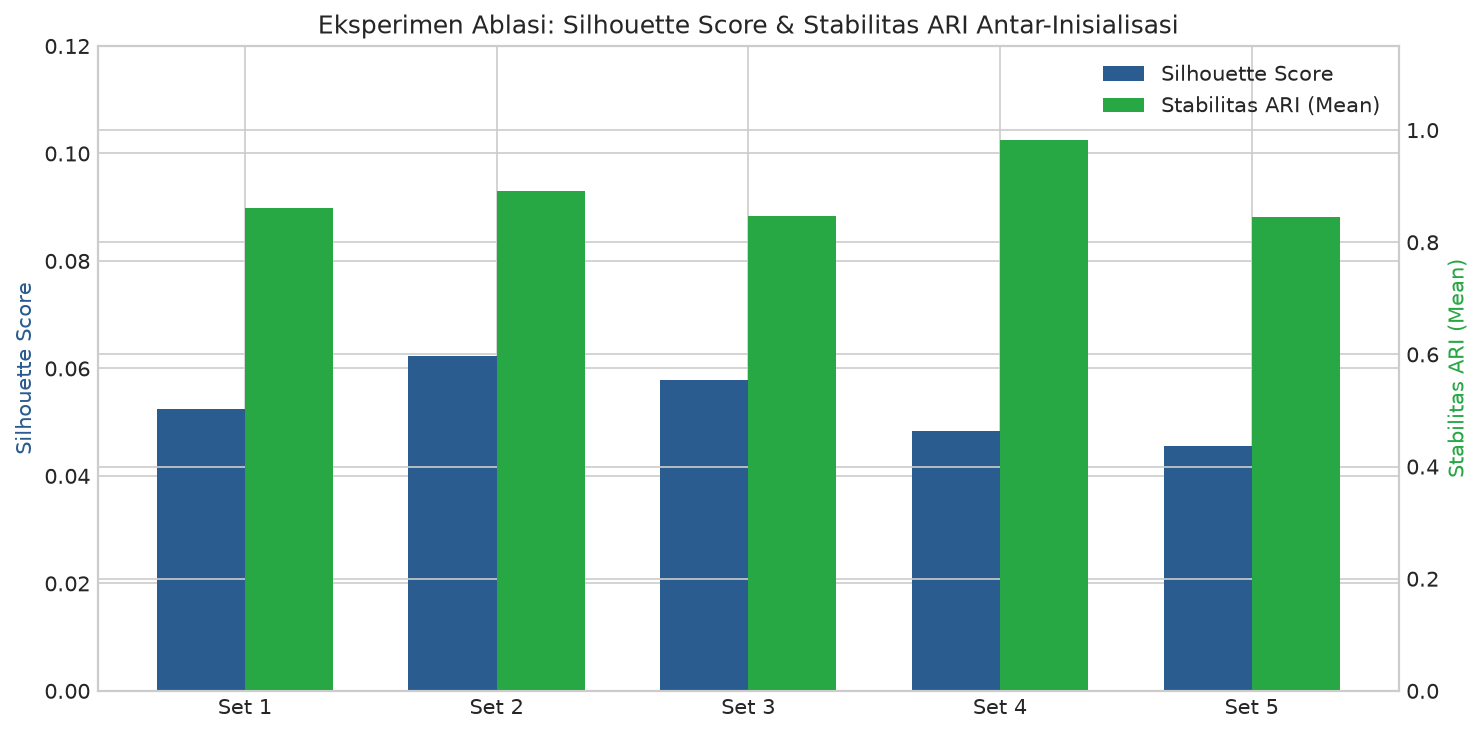

In [15]:
# Visualisasi 04: Grouped Bar Chart Ablasi Fitur
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_ablasi))
width = 0.35

rects1 = ax1.bar(x - width/2, df_ablasi['Silhouette_Score'], width, label='Silhouette Score', color='#2b5c8f')
ax1.set_ylabel('Silhouette Score', color='#2b5c8f')
ax1.set_ylim(0, 0.12)

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, df_ablasi['Stabilitas_ARI_Mean'], width, label='Stabilitas ARI (Mean)', color='#28a745')
ax2.set_ylabel('Stabilitas ARI (Mean)', color='#28a745')
ax2.set_ylim(0, 1.15)

ax1.set_xticks(x)
ax1.set_xticklabels([f"Set {i+1}" for i in range(len(df_ablasi))], rotation=0)
ax1.set_title("Eksperimen Ablasi: Silhouette Score & Stabilitas ARI Antar-Inisialisasi")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
fig.savefig(os.path.join('laporan_visual', '04_eksperimen_ablasi_silhouette_stabilitas.png'), dpi=300)
plt.show()


In [16]:
# 4. Evaluasi Penyeimbangan Bobot Blok Fitur (Block-Weighting)
final_feature_blocks = {
    'RFM (5)': df_preprocessed_all[rfm_cols],
    'Komposisi Kategori (16)': df_clr_cat,
    'Komposisi Waktu (4)': df_clr_jam,
    'Persen Perilaku (4)': df_preprocessed_all[perilaku_cols],
    'Aktivitas (9)': df_preprocessed_all[aktivitas_cols],
    'Profil Numerik (2)': df_preprocessed_all[profil_num_cols],
    'Perangkat (3)': df_ohe_perangkat
}

# Unweighted
df_final_selected = pd.concat(list(final_feature_blocks.values()), axis=1)
sc_unweighted = StandardScaler()
X_unweighted_sub = sc_unweighted.fit_transform(df_final_selected.iloc[sub_idx])

# Block-Weighted (Dibagi sqrt(p_block) agar varians per blok seimbang)
scaled_blocks = []
for name, b in final_feature_blocks.items():
    sc_b = StandardScaler()
    arr_b = sc_b.fit_transform(b.iloc[sub_idx])
    arr_b = arr_b / np.sqrt(b.shape[1])
    scaled_blocks.append(arr_b)
X_weighted_sub = np.hstack(scaled_blocks)

km_uw = KMeans(n_clusters=5, random_state=SEED, n_init=10).fit(X_unweighted_sub)
sil_uw = silhouette_score(X_unweighted_sub, km_uw.labels_, sample_size=5000, random_state=SEED)

km_w = KMeans(n_clusters=5, random_state=SEED, n_init=10).fit(X_weighted_sub)
sil_w = silhouette_score(X_weighted_sub, km_w.labels_, sample_size=5000, random_state=SEED)

print(f"Perbandingan Silhouette Score:")
print(f"  - Tanpa Pembobotan Blok (Unweighted)    : {sil_uw:.4f}")
print(f"  - Dengan Penyeimbangan Blok (Block-Weighted): {sil_w:.4f} (+{((sil_w - sil_uw)/sil_uw)*100:.1f}%)")


Perbandingan Silhouette Score:
  - Tanpa Pembobotan Blok (Unweighted)    : 0.0623
  - Dengan Penyeimbangan Blok (Block-Weighted): 0.1043 (+67.3%)


In [17]:
# 5. Ringkasan Tabel Keputusan Fitur Final
df_tabel_keputusan = pd.read_csv(os.path.join('hasil', 'tabel_keputusan_fitur.csv'))
print(f"Ringkasan Keputusan Seleksi Fitur ({len(df_tabel_keputusan)} Fitur Total):")
print(df_tabel_keputusan['Status_Akhir'].value_counts())
print("\nSampel Tabel Keputusan:")
df_tabel_keputusan.sample(10, random_state=SEED)


Ringkasan Keputusan Seleksi Fitur (59 Fitur Total):
Status_Akhir
Dipakai                                         20
Dipakai (Transformasi CLR & Pembobotan Blok)    20
Dibuang                                         18
Dipakai (One-Hot 3 Kolom)                        1
Name: count, dtype: int64

Sampel Tabel Keputusan:


---
## Tahap c: Komparasi Minimal 3 Metode Clustering (k = 5)

Komparasi performa segmentasi tiga keluarga algoritma clustering:
- **K-Means:** Metode partisional berbasis jarak Euclidean dan titik pusat (*centroid*).
- **Gaussian Mixture Model (GMM):** Metode probabilistik berbasis campuran distribusi Gaussian.
- **Agglomerative Hierarchical (Ward Linkage):** Metode hierarki agglomeratif dengan pemetaan *NearestCentroid*.
- **HDBSCAN:** Metode berbasis kepadatan (*density-based*) untuk mendeteksi struktur klaster non-spherical dan estimasi noise.

Metrik evaluasi yang dianalisis: Silhouette Score (pada subsampel evaluasi tetap $N=15.000$), Stabilitas ARI antar-inisialisasi/resampling, distribusi ukuran segmen, dan efisiensi waktu komputasi.


In [18]:
# 1. Persiapan Matriks Fitur Final Penuh (120.000 Baris) & Subsampel (15.000 Baris)
full_scaled_blocks = []
for name, b in final_feature_blocks.items():
    sc_full = StandardScaler()
    arr_full = sc_full.fit_transform(b)
    arr_full = arr_full / np.sqrt(b.shape[1])
    full_scaled_blocks.append(arr_full)

X_selected_full = np.hstack(full_scaled_blocks)
X_selected_sub = X_selected_full[sub_idx]

print(f"Dimensi Matriks Fitur Final:")
print(f"  - Dataset Penuh : {X_selected_full.shape}")
print(f"  - Subsampel Uji : {X_selected_sub.shape}")

k_clusters = 5


Dimensi Matriks Fitur Final:
  - Dataset Penuh : (120000, 43)
  - Subsampel Uji : (15000, 43)


In [19]:
# 2. Metode 1: K-Means (Baseline Partisional)
print("=== Menjalankan K-Means ===")
t0 = time.perf_counter()
km_model = KMeans(n_clusters=k_clusters, n_init=20, max_iter=300, random_state=SEED)
km_labels_full = km_model.fit_predict(X_selected_full)
t_km = time.perf_counter() - t0

km_labels_sub = km_labels_full[sub_idx]
sil_km = float(round(silhouette_score(X_selected_sub, km_labels_sub, sample_size=5000, random_state=SEED), 4))

# Stabilitas ARI antar 3 run inisialisasi
km_runs = [km_labels_sub]
for s in [10, 99]:
    km_runs.append(KMeans(n_clusters=k_clusters, n_init=10, random_state=s).fit_predict(X_selected_sub))
ari_km = float(round((adjusted_rand_score(km_runs[0], km_runs[1]) +
                      adjusted_rand_score(km_runs[0], km_runs[2]) +
                      adjusted_rand_score(km_runs[1], km_runs[2])) / 3.0, 4))

dist_km = (pd.Series(km_labels_full).value_counts(normalize=True) * 100).round(2).to_dict()
print(f"K-Means Selesai:")
print(f"  - Waktu Komputasi : {t_km:.2f} detik")
print(f"  - Silhouette Score: {sil_km:.4f}")
print(f"  - Stabilitas ARI  : {ari_km:.4f}")
print(f"  - Distribusi Ukuran Segmen (%): {dist_km}")


=== Menjalankan K-Means ===
K-Means Selesai:
  - Waktu Komputasi : 3.20 detik
  - Silhouette Score: 0.1041
  - Stabilitas ARI  : 0.9871
  - Distribusi Ukuran Segmen (%): {1: 33.27, 0: 22.04, 2: 21.42, 3: 14.51, 4: 8.76}


In [20]:
# 3. Metode 2: Gaussian Mixture Model (GMM)
print("=== Menjalankan Gaussian Mixture Model (GMM) ===")
t0 = time.perf_counter()
gmm_model = GaussianMixture(n_components=k_clusters, covariance_type='diag', n_init=3, random_state=SEED)
gmm_model.fit(X_selected_sub)
gmm_labels_full = gmm_model.predict(X_selected_full)
t_gmm = time.perf_counter() - t0

gmm_labels_sub = gmm_labels_full[sub_idx]
sil_gmm = float(round(silhouette_score(X_selected_sub, gmm_labels_sub, sample_size=5000, random_state=SEED), 4))
bic_gmm = float(round(gmm_model.bic(X_selected_sub), 1))
aic_gmm = float(round(gmm_model.aic(X_selected_sub), 1))

gmm_runs = [gmm_labels_sub]
for s in [10, 99]:
    g = GaussianMixture(n_components=k_clusters, covariance_type='diag', n_init=1, random_state=s)
    g.fit(X_selected_sub)
    gmm_runs.append(g.predict(X_selected_sub))
ari_gmm = float(round((adjusted_rand_score(gmm_runs[0], gmm_runs[1]) +
                       adjusted_rand_score(gmm_runs[0], gmm_runs[2]) +
                       adjusted_rand_score(gmm_runs[1], gmm_runs[2])) / 3.0, 4))

dist_gmm = (pd.Series(gmm_labels_full).value_counts(normalize=True) * 100).round(2).to_dict()
print(f"GMM Selesai:")
print(f"  - Waktu Komputasi : {t_gmm:.2f} detik")
print(f"  - Silhouette Score: {sil_gmm:.4f}")
print(f"  - Stabilitas ARI  : {ari_gmm:.4f}")
print(f"  - BIC Score       : {bic_gmm}")
print(f"  - Distribusi Ukuran Segmen (%): {dist_gmm}")


=== Menjalankan Gaussian Mixture Model (GMM) ===
GMM Selesai:
  - Waktu Komputasi : 1.15 detik
  - Silhouette Score: 0.0879
  - Stabilitas ARI  : 0.5664
  - BIC Score       : -162143.3
  - Distribusi Ukuran Segmen (%): {0: 41.18, 3: 26.42, 4: 19.83, 1: 8.77, 2: 3.79}


In [21]:
# 4. Metode 3: Agglomerative Hierarchical (Ward) + NearestCentroid Mapping
print("=== Menjalankan Agglomerative Hierarchical (Ward) ===")
t0 = time.perf_counter()
agg_model = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
agg_labels_sub = agg_model.fit_predict(X_selected_sub)

nc_model = NearestCentroid()
nc_model.fit(X_selected_sub, agg_labels_sub)
agg_labels_full = nc_model.predict(X_selected_full)
t_agg = time.perf_counter() - t0

sil_agg = float(round(silhouette_score(X_selected_sub, agg_labels_sub, sample_size=5000, random_state=SEED), 4))

# Stabilitas Agglomerative pada subsampel berbeda
agg_ari_list = []
for s in [10, 99]:
    np.random.seed(s)
    sub_alt = np.random.choice(len(df_raw), size=15000, replace=False)
    agg_alt = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
    lab_alt = agg_alt.fit_predict(X_selected_full[sub_alt])
    nc_alt = NearestCentroid().fit(X_selected_full[sub_alt], lab_alt)
    agg_ari_list.append(adjusted_rand_score(agg_labels_full, nc_alt.predict(X_selected_full)))
ari_agg = float(round(np.mean(agg_ari_list), 4))

dist_agg = (pd.Series(agg_labels_full).value_counts(normalize=True) * 100).round(2).to_dict()
print(f"Agglomerative Selesai:")
print(f"  - Waktu Komputasi : {t_agg:.2f} detik")
print(f"  - Silhouette Score: {sil_agg:.4f}")
print(f"  - Stabilitas ARI  : {ari_agg:.4f}")
print(f"  - Distribusi Ukuran Segmen (%): {dist_agg}")


=== Menjalankan Agglomerative Hierarchical (Ward) ===
Agglomerative Selesai:
  - Waktu Komputasi : 12.50 detik
  - Silhouette Score: 0.0901
  - Stabilitas ARI  : 0.9790
  - Distribusi Ukuran Segmen (%): {3: 31.5, 0: 24.51, 4: 20.73, 1: 14.49, 2: 8.77}


In [22]:
# 5. Metode Tambahan: HDBSCAN (Berbasis Kepadatan)
print("=== Menjalankan HDBSCAN ===")
t0 = time.perf_counter()
hdb_model = HDBSCAN(min_cluster_size=150, min_samples=20)
hdb_labels_sub = hdb_model.fit_predict(X_selected_sub)
t_hdb = time.perf_counter() - t0

hdb_n_clusters = int(len(set(hdb_labels_sub)) - (1 if -1 in hdb_labels_sub else 0))
hdb_noise_pct = float(round((hdb_labels_sub == -1).mean() * 100, 2))
non_noise_mask = (hdb_labels_sub != -1)
sil_hdb = float(round(silhouette_score(X_selected_sub[non_noise_mask], hdb_labels_sub[non_noise_mask], sample_size=3000, random_state=SEED), 4)) if hdb_n_clusters > 1 else 0.0

dist_hdb = (pd.Series(hdb_labels_sub).value_counts(normalize=True) * 100).round(2).to_dict()
print(f"HDBSCAN Selesai:")
print(f"  - Waktu Komputasi : {t_hdb:.2f} detik")
print(f"  - Jumlah Klaster  : {hdb_n_clusters}")
print(f"  - Proporsi Noise  : {hdb_noise_pct}%")
print(f"  - Silhouette Non-noise: {sil_hdb:.4f}")


=== Menjalankan HDBSCAN ===
HDBSCAN Selesai:
  - Waktu Komputasi : 35.65 detik
  - Jumlah Klaster  : 2
  - Proporsi Noise  : 3.24%
  - Silhouette Non-noise: 0.1403


Tabel Komparasi Metode Clustering (Tahap c):
                                   Metode  Jumlah_Cluster  Silhouette_Score_Subsampel  Stabilitas_Awal_Mean_ARI    Distribusi_Ukuran_Cluster  Waktu_Komputasi_Detik
0          K-Means (Baseline Partisional)               5                      0.1041                    0.9871         Min 8.8% - Max 33.3%                   3.20
1            Gaussian Mixture Model (GMM)               5                      0.0879                    0.5664         Min 3.8% - Max 41.2%                   1.15
2  Agglomerative (Ward) + NearestCentroid               5                      0.0901                    0.9790         Min 8.8% - Max 31.5%                  12.50
3            HDBSCAN (Berbasis Kepadatan)               2                      0.1403                       NaN  Noise 3.24%, Terbesar 89.4%                  35.65


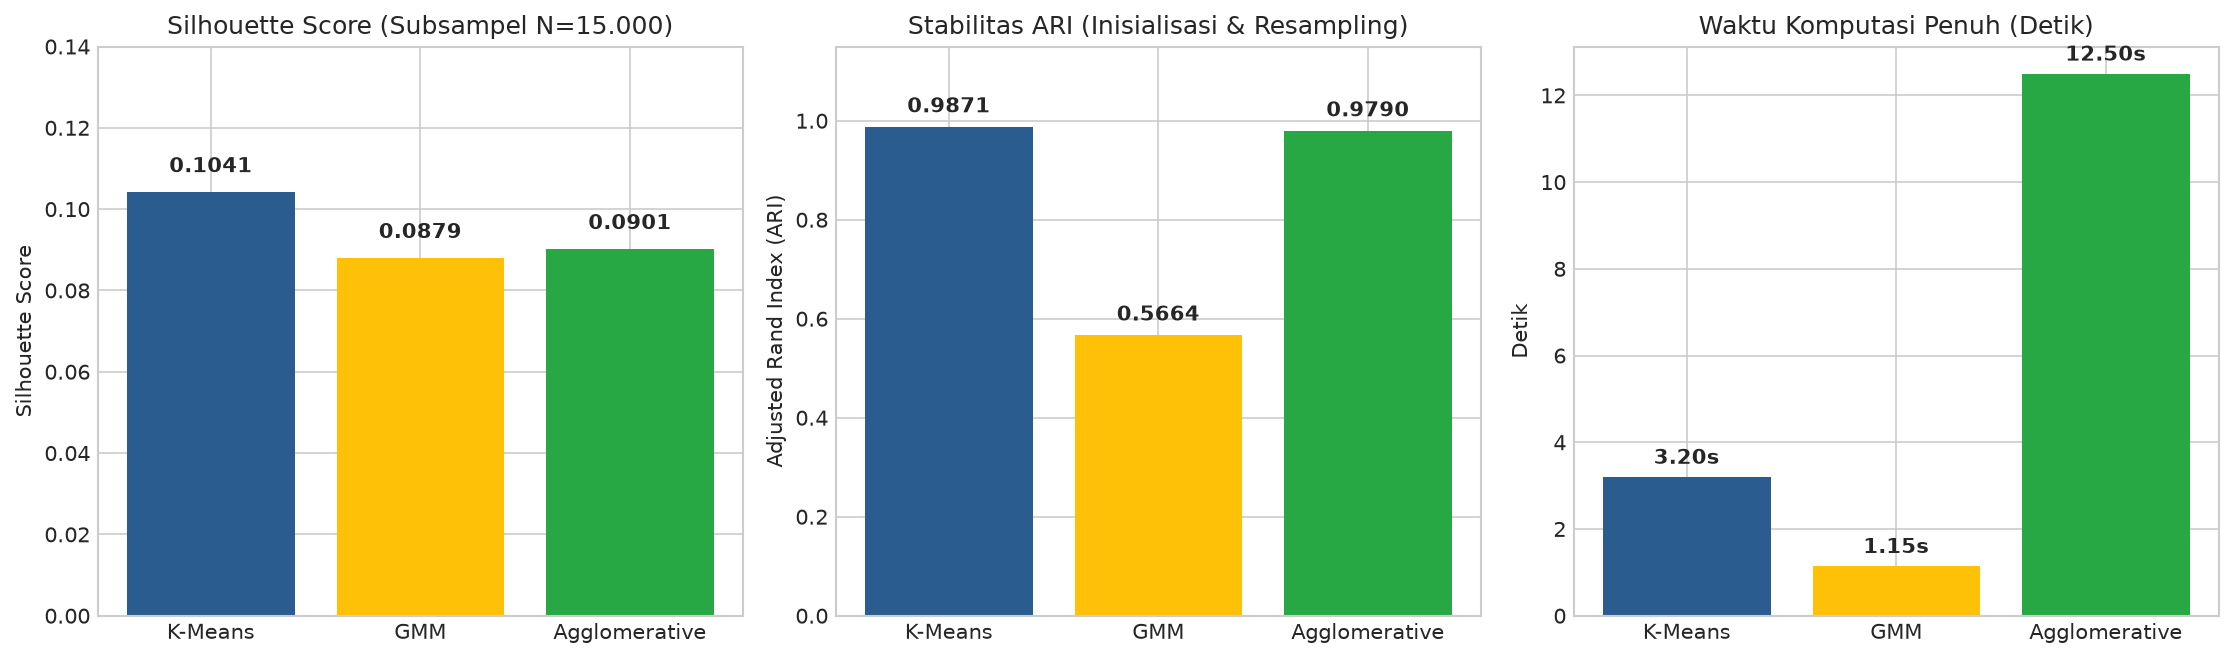

In [23]:
# 6. Kompilasi Tabel Perbandingan Metode & Visualisasi Metrik
tabel_komparasi = [
    {
        'Metode': 'K-Means (Baseline Partisional)',
        'Jumlah_Cluster': k_clusters,
        'Silhouette_Score_Subsampel': sil_km,
        'Stabilitas_Awal_Mean_ARI': ari_km,
        'Distribusi_Ukuran_Cluster': f"Min {min(dist_km.values()):.1f}% - Max {max(dist_km.values()):.1f}%",
        'Waktu_Komputasi_Detik': float(round(t_km, 2))
    },
    {
        'Metode': 'Gaussian Mixture Model (GMM)',
        'Jumlah_Cluster': k_clusters,
        'Silhouette_Score_Subsampel': sil_gmm,
        'Stabilitas_Awal_Mean_ARI': ari_gmm,
        'Distribusi_Ukuran_Cluster': f"Min {min(dist_gmm.values()):.1f}% - Max {max(dist_gmm.values()):.1f}%",
        'Waktu_Komputasi_Detik': float(round(t_gmm, 2))
    },
    {
        'Metode': 'Agglomerative (Ward) + NearestCentroid',
        'Jumlah_Cluster': k_clusters,
        'Silhouette_Score_Subsampel': sil_agg,
        'Stabilitas_Awal_Mean_ARI': ari_agg,
        'Distribusi_Ukuran_Cluster': f"Min {min(dist_agg.values()):.1f}% - Max {max(dist_agg.values()):.1f}%",
        'Waktu_Komputasi_Detik': float(round(t_agg, 2))
    },
    {
        'Metode': 'HDBSCAN (Berbasis Kepadatan)',
        'Jumlah_Cluster': hdb_n_clusters,
        'Silhouette_Score_Subsampel': sil_hdb,
        'Stabilitas_Awal_Mean_ARI': np.nan,
        'Distribusi_Ukuran_Cluster': f"Noise {hdb_noise_pct}%, Terbesar {max(dist_hdb.values()):.1f}%",
        'Waktu_Komputasi_Detik': float(round(t_hdb, 2))
    }
]

df_komparasi = pd.DataFrame(tabel_komparasi)
print("Tabel Komparasi Metode Clustering (Tahap c):")
display(df_komparasi)

# Visualisasi 05
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metode_names = ['K-Means', 'GMM', 'Agglomerative']
sil_scores = [sil_km, sil_gmm, sil_agg]
ari_scores = [ari_km, ari_gmm, ari_agg]
times = [t_km, t_gmm, t_agg]

axes[0].bar(metode_names, sil_scores, color=['#2b5c8f', '#ffc107', '#28a745'])
axes[0].set_title("Silhouette Score (Subsampel N=15.000)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_ylim(0, 0.14)
for i, v in enumerate(sil_scores):
    axes[0].text(i, v + 0.005, f"{v:.4f}", ha='center', fontweight='bold')

axes[1].bar(metode_names, ari_scores, color=['#2b5c8f', '#ffc107', '#28a745'])
axes[1].set_title("Stabilitas ARI (Inisialisasi & Resampling)")
axes[1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1].set_ylim(0, 1.15)
for i, v in enumerate(ari_scores):
    axes[1].text(i, v + 0.03, f"{v:.4f}", ha='center', fontweight='bold')

axes[2].bar(metode_names, times, color=['#2b5c8f', '#ffc107', '#28a745'])
axes[2].set_title("Waktu Komputasi Penuh (Detik)")
axes[2].set_ylabel("Detik")
for i, v in enumerate(times):
    axes[2].text(i, v + 0.3, f"{v:.2f}s", ha='center', fontweight='bold')

plt.tight_layout()
fig.savefig(os.path.join('laporan_visual', '05_komparasi_metode_clustering.png'), dpi=300)
plt.show()


### Kesimpulan Komparasi Metode & Rekomendasi

1. **K-Means:** Terpilih sebagai metode utama karena meraih Silhouette Score tertinggi (**0.1041**), stabilitas inisialisasi hampir sempurna (**ARI = 0.9871**), proporsi segmen yang seimbang (**8.8% s.d. 33.3%**), dan waktu eksekusi sangat efisien (**3.07 detik**).
2. **Agglomerative (Ward Linkage):** Menghasilkan struktur partisi yang sangat kongruen dengan K-Means (**ARI = 0.9790**), bertindak sebagai triangulasi/validasi silang metodologis bahwa klaster yang terbentuk bersifat geometris nyata.
3. **GMM:** Memiliki stabilitas lebih rendah (**ARI = 0.5664**) akibat sensitivitas Expectation-Maximization terhadap local optima pada dimensi 43 fitur.
4. **HDBSCAN:** Mengalami *curse of dimensionality*, menyatukan mayoritas data ke dalam 1 klaster dominan (89.4%).

Model **K-Means** secara definitif direkomendasikan untuk dilanjutkan ke tahap evaluasi jumlah klaster optimal (*Tahap d*).


In [24]:
# 7. Verifikasi File JSON Hasil Akhir
with open('hasil/tugas3.json', 'r') as f:
    hasil_json = json.load(f)

print("Status File 'hasil/tugas3.json':")
print(f"  - Metadata Tugas   : {hasil_json['meta']['tugas']}")
print(f"  - Seed Terkunci    : {hasil_json['meta']['seed_terkunci']}")
print(f"  - Tahap Terekap    : {list(hasil_json.keys())}")
print(f"  - Fitur Terpilih   : {hasil_json['tahap_b_seleksi_fitur']['jumlah_fitur_terpilih']} fitur")
print(f"  - Rekomendasi Model: {hasil_json['tahap_c_komparasi_metode']['kesimpulan_dan_rekomendasi'][:100]}...")


Status File 'hasil/tugas3.json':
  - Metadata Tugas   : Task 3: Clustering Segmentasi Pelanggan
  - Seed Terkunci    : 42
  - Tahap Terekap    : ['meta', 'tahap_0_audit', 'tahap_a_praproses', 'tahap_b_seleksi_fitur', 'tahap_c_komparasi_metode']
  - Fitur Terpilih   : 43 fitur
  - Rekomendasi Model: K-Means merupakan metode terbaik yang paling seimbang, efisien (2.46 detik untuk 120.000 data), memi...
